In [41]:
# ------------------------------
# Importing necessary libraries
# ------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, 
                             log_loss, confusion_matrix, classification_report)
import xgboost as xgb
import lightgbm as lgb
import shap
from tensorflow import keras
from tensorflow.keras import layers
import warnings
warnings.filterwarnings('ignore')

print("Successfully loaded all libraries!")

Successfully loaded all libraries!


In [42]:
# -----------------
# Loading datasets
# -----------------

df_dataset_a = pd.read_csv('../data/processed/football_dataset_a_all_seasons.csv')
df_dataset_b = pd.read_csv('../data/processed/football_dataset_b_with_odds.csv')

print(f"Dataset A: {df_dataset_a.shape}")
print(f"Dataset B: {df_dataset_b.shape}")

Dataset A: (19833, 49)
Dataset B: (10705, 55)


In [43]:
# ---------------------------------------
# Data preparation and train/test split
# ---------------------------------------

def prepare_data(df, without_odds=True):
    feature_cols = [col for col in df.columns 
                    if col not in ['Date', 'HomeTeam', 'AwayTeam', 'FTR', 'league', 'season']]
    if  without_odds:
        odds_cols = ['AvgH', 'AvgD', 'AvgA', 'MaxH', 'MaxD', 'MaxA']
        feature_cols = [col for col in feature_cols if col not in odds_cols]
    
    X = df[feature_cols].astype(float)
    le = LabelEncoder()
    y = le.fit_transform(df['FTR'])
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    return X_train, X_test, y_train, y_test, le, feature_cols


X_train_b_odds, X_test_b_odds, y_train_b, y_test_b, le_b, features_b_odds = prepare_data(df_dataset_b, without_odds=False)

print(f"Dataset B WITH odds:")
print(f"  X_train: {X_train_b_odds.shape}")
print(f"  X_test: {X_test_b_odds.shape}")
print(f"  Features: {len(features_b_odds)}")

X_train_b_no_odds, X_test_b_no_odds, y_train_b, y_test_b, le_b, features_b_no_odds = prepare_data(df_dataset_b, without_odds=True)

print(f"Dataset B WITHOUT odds:")
print(f"  X_train: {X_train_b_no_odds.shape}")
print(f"  X_test: {X_test_b_no_odds.shape}")
print(f"  Features: {len(features_b_no_odds)}")

X_train_a, X_test_a, y_train_a, y_test_a, le_a, features_a = prepare_data(df_dataset_a, without_odds=True)

print(f"Dataset A WITHOUT odds:")
print(f"  X_train: {X_train_a.shape}")
print(f"  X_test: {X_test_a.shape}")
print(f"  Features: {len(features_a)}")

Dataset B WITH odds:
  X_train: (8564, 49)
  X_test: (2141, 49)
  Features: 49
Dataset B WITHOUT odds:
  X_train: (8564, 43)
  X_test: (2141, 43)
  Features: 43
Dataset A WITHOUT odds:
  X_train: (15866, 43)
  X_test: (3967, 43)
  Features: 43


In [44]:
# -------------------------------
# Training and evaluating models
# -------------------------------

def train_and_evaluate(model, X_train, X_test, y_train, y_test, model_name):
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    roc_auc = roc_auc_score(y_test, y_pred_proba, multi_class='ovr')
    log_loss_val = log_loss(y_test, y_pred_proba)
    
    results = {
        'Model': model_name,
        'Accuracy': accuracy,
        'F1': f1,
        'ROC-AUC': roc_auc,
        'Log Loss': log_loss_val
    }
    
    return results, model, y_pred, y_pred_proba

all_results = []

print("=" * 70)
print("PHASE 1: Dataset B WITH ODDS (4 models)")
print("=" * 70)

# Logistic regression
print("\n1. Logistic regression...")
lr_odds = LogisticRegression(max_iter=1000, random_state=42)
results_lr_odds, model_lr_odds, _, _ = train_and_evaluate(
    lr_odds, X_train_b_odds, X_test_b_odds, y_train_b, y_test_b, 
    "LR (Dataset B + Odds)"
)
all_results.append(results_lr_odds)
print(f"  Accuracy: {results_lr_odds['Accuracy']:.4f}")

# Random Forest
print("\n2. Random Forest...")
rf_odds = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
results_rf_odds, model_rf_odds, _, _ = train_and_evaluate(
    rf_odds, X_train_b_odds, X_test_b_odds, y_train_b, y_test_b,
    "RF (Dataset B + Odds)"
)
all_results.append(results_rf_odds)
print(f"  Accuracy: {results_rf_odds['Accuracy']:.4f}")

# XGBoost
print("\n3. XGBoost...")
xgb_odds = xgb.XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbosity=0)
results_xgb_odds, model_xgb_odds, _, _ = train_and_evaluate(
    xgb_odds, X_train_b_odds, X_test_b_odds, y_train_b, y_test_b,
    "XGBoost (Dataset B + Odds)"
)
all_results.append(results_xgb_odds)
print(f"  Accuracy: {results_xgb_odds['Accuracy']:.4f}")

print("\n" + "=" * 70)
print("PHASE 2: Dataset B WITHOUT ODDS (4 models)")
print("=" * 70)

# Logistic regression
print("\n1. Logistic regression...")
lr_no_odds = LogisticRegression(max_iter=1000, random_state=42)
results_lr_no_odds, model_lr_no_odds, _, _ = train_and_evaluate(
    lr_no_odds, X_train_b_no_odds, X_test_b_no_odds, y_train_b, y_test_b,
    "LR (Dataset B no Odds)"
)
all_results.append(results_lr_no_odds)
print(f"  Accuracy: {results_lr_no_odds['Accuracy']:.4f}")

# Random Forest
print("\n2. Random Forest...")
rf_no_odds = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
results_rf_no_odds, model_rf_no_odds, _, _ = train_and_evaluate(
    rf_no_odds, X_train_b_no_odds, X_test_b_no_odds, y_train_b, y_test_b,
    "RF (Dataset B no Odds)"
)
all_results.append(results_rf_no_odds)
print(f"  Accuracy: {results_rf_no_odds['Accuracy']:.4f}")

# XGBoost
print("\n3. XGBoost...")
xgb_no_odds = xgb.XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbosity=0)
results_xgb_no_odds, model_xgb_no_odds, _, _ = train_and_evaluate(
    xgb_no_odds, X_train_b_no_odds, X_test_b_no_odds, y_train_b, y_test_b,
    "XGBoost (Dataset B no Odds)"
)
all_results.append(results_xgb_no_odds)
print(f"  Accuracy: {results_xgb_no_odds['Accuracy']:.4f}")

print("\n" + "=" * 70)
print("PHASE 3: Dataset A WITHOUT ODDS (4 models)")
print("=" * 70)

# Logistic Regression
print("\n1. Logistic Regression...")
lr_all = LogisticRegression(max_iter=1000, random_state=42)
results_lr_all, model_lr_all, _, _ = train_and_evaluate(
    lr_all, X_train_a, X_test_a, y_train_a, y_test_a,
    "LR (Dataset A no Odds)"
)
all_results.append(results_lr_all)
print(f"  Accuracy: {results_lr_all['Accuracy']:.4f}")

# Random Forest
print("\n2. Random Forest...")
rf_all = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
results_rf_all, model_rf_all, _, _ = train_and_evaluate(
    rf_all, X_train_a, X_test_a, y_train_a, y_test_a,
    "RF (Dataset A no Odds)"
)
all_results.append(results_rf_all)
print(f"  Accuracy: {results_rf_all['Accuracy']:.4f}")

# XGBoost
print("\n3. XGBoost...")
xgb_all = xgb.XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbosity=0)
results_xgb_all, model_xgb_all, _, _ = train_and_evaluate(
    xgb_all, X_train_a, X_test_a, y_train_a, y_test_a,
    "XGBoost (Dataset A no Odds)"
)
all_results.append(results_xgb_all)
print(f"  Accuracy: {results_xgb_all['Accuracy']:.4f}")

results_df = pd.DataFrame(all_results)
print("\n" + "=" * 70)
print("SUMMARY OF ALL MODELS")
print("=" * 70)
print(results_df.to_string(index=False))

PHASE 1: Dataset B WITH ODDS (4 models)

1. Logistic regression...
  Accuracy: 0.5521

2. Random Forest...
  Accuracy: 0.5250

3. XGBoost...
  Accuracy: 0.5199

PHASE 2: Dataset B WITHOUT ODDS (4 models)

1. Logistic regression...
  Accuracy: 0.5493

2. Random Forest...
  Accuracy: 0.5301

3. XGBoost...
  Accuracy: 0.5068

PHASE 3: Dataset A WITHOUT ODDS (4 models)

1. Logistic Regression...
  Accuracy: 0.5216

2. Random Forest...
  Accuracy: 0.5193

3. XGBoost...
  Accuracy: 0.4989

SUMMARY OF ALL MODELS
                      Model  Accuracy       F1  ROC-AUC  Log Loss
      LR (Dataset B + Odds)  0.552078 0.472546 0.673335  0.971518
      RF (Dataset B + Odds)  0.524988 0.486910 0.659245  0.993668
 XGBoost (Dataset B + Odds)  0.519851 0.497207 0.651931  1.064293
     LR (Dataset B no Odds)  0.549276 0.472150 0.667891  0.976925
     RF (Dataset B no Odds)  0.530126 0.486098 0.659155  0.990688
XGBoost (Dataset B no Odds)  0.506773 0.482338 0.640890  1.062362
     LR (Dataset A no Odds)

In [45]:
# ----------------------------------------------------------------------------------------------
# Optimization Phase 1: Logistic Regression with Normalization and Tuning - Dataset B with odds
# ----------------------------------------------------------------------------------------------

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, cross_val_score

optimized_all_results = []

scaler = StandardScaler()
X_train_b_odds_scaled = scaler.fit_transform(X_train_b_odds)
X_test_b_odds_scaled = scaler.transform(X_test_b_odds)

param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'saga'],
    'max_iter': [1000, 2000]
}

lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train_b_odds_scaled, y_train_b)

print(50*"=")
print("DATASET B WITH ODDS")
print(50*"=")
print(f"\nBest parameters: {lr_grid.best_params_}")
print(f"Best CV accuracy: {lr_grid.best_score_:.4f}")

best_lr_b_odds = lr_grid.best_estimator_
y_pred_lr = best_lr_b_odds.predict(X_test_b_odds_scaled)
y_pred_proba_lr = best_lr_b_odds.predict_proba(X_test_b_odds_scaled)

accuracy_lr = accuracy_score(y_test_b, y_pred_lr)
f1_lr = f1_score(y_test_b, y_pred_lr, average='weighted')
roc_auc_lr = roc_auc_score(y_test_b, y_pred_proba_lr, multi_class='ovr')
log_loss_lr = log_loss(y_test_b, y_pred_proba_lr)

optimized_all_results.append([accuracy_lr, f1_lr, roc_auc_lr, log_loss_lr])

print(f"\nTest Accuracy: {accuracy_lr:.4f}")
print(f"Test F1: {f1_lr:.4f}")
print(f"Test ROC-AUC: {roc_auc_lr:.4f}")
print(f"Test Log Loss: {log_loss_lr:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
DATASET B WITH ODDS

Best parameters: {'C': 0.01, 'max_iter': 1000, 'solver': 'lbfgs'}
Best CV accuracy: 0.5281

Test Accuracy: 0.5427
Test F1: 0.4686
Test ROC-AUC: 0.6731
Test Log Loss: 0.9736


In [46]:
# -------------------------------------------------------------------------------------------------
# Optimization Phase 1: Logistic Regression with Normalization and Tuning - Dataset B without odds
# -------------------------------------------------------------------------------------------------

scaler = StandardScaler()
X_train_b_no_odds_scaled = scaler.fit_transform(X_train_b_no_odds)
X_test_b_no_odds_scaled = scaler.transform(X_test_b_no_odds)

lr_grid.fit(X_train_b_no_odds_scaled, y_train_b)

print(50*"=")
print("DATASET B WITHOUT ODDS")
print(50*"=")
print(f"\nBest parameters: {lr_grid.best_params_}")
print(f"Best CV accuracy: {lr_grid.best_score_:.4f}")

best_lr_b_no_odds = lr_grid.best_estimator_
y_pred_lr = best_lr_b_no_odds.predict(X_test_b_no_odds_scaled)
y_pred_proba_lr = best_lr_b_no_odds.predict_proba(X_test_b_no_odds_scaled)

accuracy_lr = accuracy_score(y_test_b, y_pred_lr)
f1_lr = f1_score(y_test_b, y_pred_lr, average='weighted')
roc_auc_lr = roc_auc_score(y_test_b, y_pred_proba_lr, multi_class='ovr')
log_loss_lr = log_loss(y_test_b, y_pred_proba_lr)

optimized_all_results.append([accuracy_lr, f1_lr, roc_auc_lr, log_loss_lr])

print(f"\nTest Accuracy: {accuracy_lr:.4f}")
print(f"Test F1: {f1_lr:.4f}")
print(f"Test ROC-AUC: {roc_auc_lr:.4f}")
print(f"Test Log Loss: {log_loss_lr:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
DATASET B WITHOUT ODDS

Best parameters: {'C': 0.01, 'max_iter': 1000, 'solver': 'saga'}
Best CV accuracy: 0.5222

Test Accuracy: 0.5437
Test F1: 0.4703
Test ROC-AUC: 0.6664
Test Log Loss: 0.9780


In [47]:
# ------------------------------------------------------------------------------------
# Optimization Phase 1: Logistic Regression with Normalization and Tuning - Dataset A
# ------------------------------------------------------------------------------------

scaler = StandardScaler()
X_train_a_scaled = scaler.fit_transform(X_train_a)
X_test_a_scaled = scaler.transform(X_test_a)

lr_grid.fit(X_train_a_scaled, y_train_a)

print(50*"=")
print("DATASET A")
print(50*"=")
print(f"\nBest parameters: {lr_grid.best_params_}")
print(f"Best CV accuracy: {lr_grid.best_score_:.4f}")

best_lr_a = lr_grid.best_estimator_
y_pred_lr = best_lr_a.predict(X_test_a_scaled)
y_pred_proba_lr = best_lr_a.predict_proba(X_test_a_scaled)

accuracy_lr = accuracy_score(y_test_a, y_pred_lr)
f1_lr = f1_score(y_test_a, y_pred_lr, average='weighted')
roc_auc_lr = roc_auc_score(y_test_a, y_pred_proba_lr, multi_class='ovr')
log_loss_lr = log_loss(y_test_a, y_pred_proba_lr)

optimized_all_results.append([accuracy_lr, f1_lr, roc_auc_lr, log_loss_lr])

print(f"\nTest Accuracy: {accuracy_lr:.4f}")
print(f"Test F1: {f1_lr:.4f}")
print(f"Test ROC-AUC: {roc_auc_lr:.4f}")
print(f"Test Log Loss: {log_loss_lr:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
DATASET A

Best parameters: {'C': 100, 'max_iter': 1000, 'solver': 'saga'}
Best CV accuracy: 0.5311

Test Accuracy: 0.5221
Test F1: 0.4441
Test ROC-AUC: 0.6600
Test Log Loss: 0.9899


In [48]:
# -----------------------------------------------------------------
# Optimization Phase 2: Random Forest Tuning - Dataset B with odds
# -----------------------------------------------------------------

from sklearn.model_selection import RandomizedSearchCV

param_grid_rf = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_depth': [None, 10, 20, 30, 40],
    'min_samples_split': [2, 5, 7, 10],
    'min_samples_leaf': [2, 3, 4, 5]
}

total_combinations = 5 * 5 * 4 * 5
print(f"Total combinations: {total_combinations}")
print(f"Using RandomizedSearchCV with 100 random combinations instead of all {total_combinations}")

rf_random = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid_rf,
    n_iter=100,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

rf_random.fit(X_train_b_odds, y_train_b)

print(50*"=")
print("DATASET B WITH ODDS")
print(50*"=")
print(f"\nBest parameters: {rf_random.best_params_}")
print(f"Best CV accuracy: {rf_random.best_score_:.4f}")

best_rf_b_odds = rf_random.best_estimator_
y_pred_rf = best_rf_b_odds.predict(X_test_b_odds)
y_pred_proba_rf = best_rf_b_odds.predict_proba(X_test_b_odds)

accuracy_rf = accuracy_score(y_test_b, y_pred_rf)
f1_rf = f1_score(y_test_b, y_pred_rf, average='weighted')
roc_auc_rf = roc_auc_score(y_test_b, y_pred_proba_rf, multi_class='ovr')
log_loss_rf = log_loss(y_test_b, y_pred_proba_rf)

optimized_all_results.append([accuracy_rf, f1_rf, roc_auc_rf, log_loss_rf])

print(f"\nTest Accuracy: {accuracy_rf:.4f}")
print(f"Test F1: {f1_rf:.4f}")
print(f"Test ROC-AUC: {roc_auc_rf:.4f}")
print(f"Test Log Loss: {log_loss_rf:.4f}")

Total combinations: 500
Using RandomizedSearchCV with 100 random combinations instead of all 500
Fitting 5 folds for each of 100 candidates, totalling 500 fits
DATASET B WITH ODDS

Best parameters: {'n_estimators': 300, 'min_samples_split': 7, 'min_samples_leaf': 4, 'max_depth': 30}
Best CV accuracy: 0.5335

Test Accuracy: 0.5362
Test F1: 0.4901
Test ROC-AUC: 0.6724
Test Log Loss: 0.9759


In [49]:
# --------------------------------------------------------------------
# Optimization Phase 2: Random Forest Tuning - Dataset B without odds
# --------------------------------------------------------------------

rf_random.fit(X_train_b_no_odds, y_train_b)

print(50*"=")
print("DATASET B WITHOUT ODDS")
print(50*"=")
print(f"\nBest parameters: {rf_random.best_params_}")
print(f"Best CV accuracy: {rf_random.best_score_:.4f}")

best_rf_b_no_odds = rf_random.best_estimator_
y_pred_rf = best_rf_b_no_odds.predict(X_test_b_no_odds)
y_pred_proba_rf = best_rf_b_no_odds.predict_proba(X_test_b_no_odds)

accuracy_rf = accuracy_score(y_test_b, y_pred_rf)
f1_rf = f1_score(y_test_b, y_pred_rf, average='weighted')
roc_auc_rf = roc_auc_score(y_test_b, y_pred_proba_rf, multi_class='ovr')
log_loss_rf = log_loss(y_test_b, y_pred_proba_rf)

optimized_all_results.append([accuracy_rf, f1_rf, roc_auc_rf, log_loss_rf])

print(f"\nTest Accuracy: {accuracy_rf:.4f}")
print(f"Test F1: {f1_rf:.4f}")
print(f"Test ROC-AUC: {roc_auc_rf:.4f}")
print(f"Test Log Loss: {log_loss_rf:.4f}")

Fitting 5 folds for each of 100 candidates, totalling 500 fits
DATASET B WITHOUT ODDS

Best parameters: {'n_estimators': 250, 'min_samples_split': 10, 'min_samples_leaf': 3, 'max_depth': 10}
Best CV accuracy: 0.5245

Test Accuracy: 0.5395
Test F1: 0.4709
Test ROC-AUC: 0.6722
Test Log Loss: 0.9752


In [50]:
# --------------------------------------------------------
# Optimization Phase 2: Random Forest Tuning - Dataset A
# --------------------------------------------------------

rf_random.fit(X_train_a, y_train_a)

print(50*"=")
print("DATASET A")
print(50*"=")
print(f"\nBest parameters: {rf_random.best_params_}")
print(f"Best CV accuracy: {rf_random.best_score_:.4f}")

best_rf_a = rf_random.best_estimator_
y_pred_rf = best_rf_a.predict(X_test_a)
y_pred_proba_rf = best_rf_a.predict_proba(X_test_a)

accuracy_rf = accuracy_score(y_test_a, y_pred_rf)
f1_rf = f1_score(y_test_a, y_pred_rf, average='weighted')
roc_auc_rf = roc_auc_score(y_test_a, y_pred_proba_rf, multi_class='ovr')
log_loss_rf = log_loss(y_test_a, y_pred_proba_rf)

optimized_all_results.append([accuracy_rf, f1_rf, roc_auc_rf, log_loss_rf])

print(f"\nTest Accuracy: {accuracy_rf:.4f}")
print(f"Test F1: {f1_rf:.4f}")
print(f"Test ROC-AUC: {roc_auc_rf:.4f}")
print(f"Test Log Loss: {log_loss_rf:.4f}")

Fitting 5 folds for each of 100 candidates, totalling 500 fits
DATASET A

Best parameters: {'n_estimators': 250, 'min_samples_split': 10, 'min_samples_leaf': 3, 'max_depth': 10}
Best CV accuracy: 0.5266

Test Accuracy: 0.5263
Test F1: 0.4487
Test ROC-AUC: 0.6566
Test Log Loss: 0.9911


In [51]:
# -----------------------------------------------------------
# Optimization Phase 3: XGBoost Tuning - Dataset B with odds
# -----------------------------------------------------------

param_grid_xgb = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

total_combinations = 4 * 4 * 4 * 3 * 3
print(f"Total combinations: {total_combinations}")
print(f"Using RandomizedSearchCV with 100 random combinations")

xgb_random = RandomizedSearchCV(
    xgb.XGBClassifier(random_state=42, n_jobs=-1, verbosity=0),
    param_grid_xgb,
    n_iter=100,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

xgb_random.fit(X_train_b_odds, y_train_b)

print(50*"=")
print("DATASET B WITH ODDS")
print(50*"=")
print(f"\nBest parameters: {xgb_random.best_params_}")
print(f"Best CV accuracy: {xgb_random.best_score_:.4f}")

best_xgb_b_odds = xgb_random.best_estimator_
y_pred_xgb = best_xgb_b_odds.predict(X_test_b_odds)
y_pred_proba_xgb = best_xgb_b_odds.predict_proba(X_test_b_odds)

accuracy_xgb = accuracy_score(y_test_b, y_pred_xgb)
f1_xgb = f1_score(y_test_b, y_pred_xgb, average='weighted')
roc_auc_xgb = roc_auc_score(y_test_b, y_pred_proba_xgb, multi_class='ovr')
log_loss_xgb = log_loss(y_test_b, y_pred_proba_xgb)

optimized_all_results.append([accuracy_xgb, f1_xgb, roc_auc_xgb, log_loss_xgb])

print(f"\nTest Accuracy: {accuracy_xgb:.4f}")
print(f"Test F1: {f1_xgb:.4f}")
print(f"Test ROC-AUC: {roc_auc_xgb:.4f}")
print(f"Test Log Loss: {log_loss_xgb:.4f}")

Total combinations: 576
Using RandomizedSearchCV with 100 random combinations
Fitting 5 folds for each of 100 candidates, totalling 500 fits
DATASET B WITH ODDS

Best parameters: {'subsample': 0.6, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
Best CV accuracy: 0.5349

Test Accuracy: 0.5465
Test F1: 0.4711
Test ROC-AUC: 0.6745
Test Log Loss: 0.9737


In [52]:
# --------------------------------------------------------------
# Optimization Phase 3: XGBoost Tuning - Dataset B without odds
# --------------------------------------------------------------

xgb_random.fit(X_train_b_no_odds, y_train_b)

print(50*"=")
print("DATASET B WITHOUT ODDS")
print(50*"=")
print(f"\nBest parameters: {xgb_random.best_params_}")
print(f"Best CV accuracy: {xgb_random.best_score_:.4f}")

best_xgb_b_no_odds = xgb_random.best_estimator_
y_pred_xgb = best_xgb_b_no_odds.predict(X_test_b_no_odds)
y_pred_proba_xgb = best_xgb_b_no_odds.predict_proba(X_test_b_no_odds)

accuracy_xgb = accuracy_score(y_test_b, y_pred_xgb)
f1_xgb = f1_score(y_test_b, y_pred_xgb, average='weighted')
roc_auc_xgb = roc_auc_score(y_test_b, y_pred_proba_xgb, multi_class='ovr')
log_loss_xgb = log_loss(y_test_b, y_pred_proba_xgb)

optimized_all_results.append([accuracy_xgb, f1_xgb, roc_auc_xgb, log_loss_xgb])

print(f"\nTest Accuracy: {accuracy_xgb:.4f}")
print(f"Test F1: {f1_xgb:.4f}")
print(f"Test ROC-AUC: {roc_auc_xgb:.4f}")
print(f"Test Log Loss: {log_loss_xgb:.4f}")

Fitting 5 folds for each of 100 candidates, totalling 500 fits
DATASET B WITHOUT ODDS

Best parameters: {'subsample': 0.6, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
Best CV accuracy: 0.5249

Test Accuracy: 0.5385
Test F1: 0.4599
Test ROC-AUC: 0.6710
Test Log Loss: 0.9813


In [53]:
# --------------------------------------------------
# Optimization Phase 3: XGBoost Tuning - Dataset A
# --------------------------------------------------

xgb_random.fit(X_train_a, y_train_a)

print(50*"=")
print("DATASET A")
print(50*"=")
print(f"\nBest parameters: {xgb_random.best_params_}")
print(f"Best CV accuracy: {xgb_random.best_score_:.4f}")

best_xgb_a = xgb_random.best_estimator_
y_pred_xgb = best_xgb_a.predict(X_test_a)
y_pred_proba_xgb = best_xgb_a.predict_proba(X_test_a)

accuracy_xgb = accuracy_score(y_test_a, y_pred_xgb)
f1_xgb = f1_score(y_test_a, y_pred_xgb, average='weighted')
roc_auc_xgb = roc_auc_score(y_test_a, y_pred_proba_xgb, multi_class='ovr')
log_loss_xgb = log_loss(y_test_a, y_pred_proba_xgb)

optimized_all_results.append([accuracy_xgb, f1_xgb, roc_auc_xgb, log_loss_xgb])

print(f"\nTest Accuracy: {accuracy_xgb:.4f}")
print(f"Test F1: {f1_xgb:.4f}")
print(f"Test ROC-AUC: {roc_auc_xgb:.4f}")
print(f"Test Log Loss: {log_loss_xgb:.4f}")

results_df = pd.DataFrame(optimized_all_results, columns=['Accuracy', 'F1', 'ROC-AUC', 'Log Loss'])
print("\n" + "=" * 70)
print("SUMMARY OF ALL MODELS OPTIMIZED")
print("=" * 70)
print(results_df.to_string(index=False))

Fitting 5 folds for each of 100 candidates, totalling 500 fits
DATASET A

Best parameters: {'subsample': 0.6, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
Best CV accuracy: 0.5272

Test Accuracy: 0.5256
Test F1: 0.4482
Test ROC-AUC: 0.6571
Test Log Loss: 0.9903

SUMMARY OF ALL MODELS OPTIMIZED
 Accuracy       F1  ROC-AUC  Log Loss
 0.542737 0.468606 0.673113  0.973595
 0.543671 0.470298 0.666448  0.977999
 0.522057 0.444127 0.660006  0.989868
 0.536198 0.490066 0.672372  0.975900
 0.539468 0.470901 0.672244  0.975233
 0.526342 0.448704 0.656621  0.991139
 0.546474 0.471128 0.674469  0.973676
 0.538533 0.459927 0.671028  0.981303
 0.525586 0.448176 0.657094  0.990289


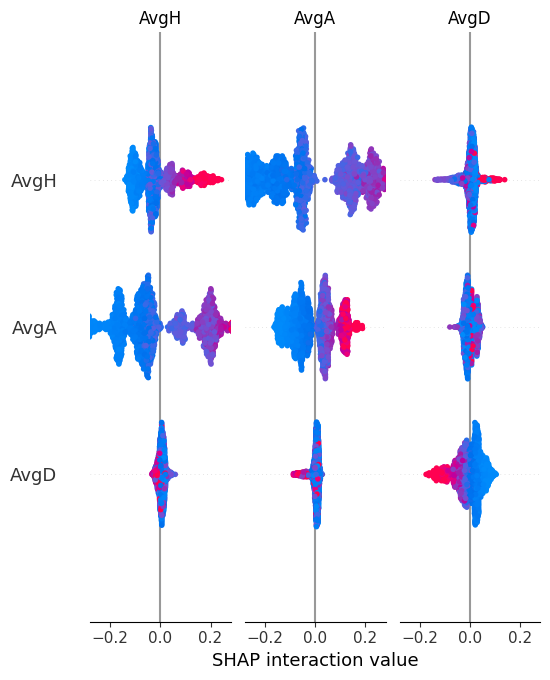

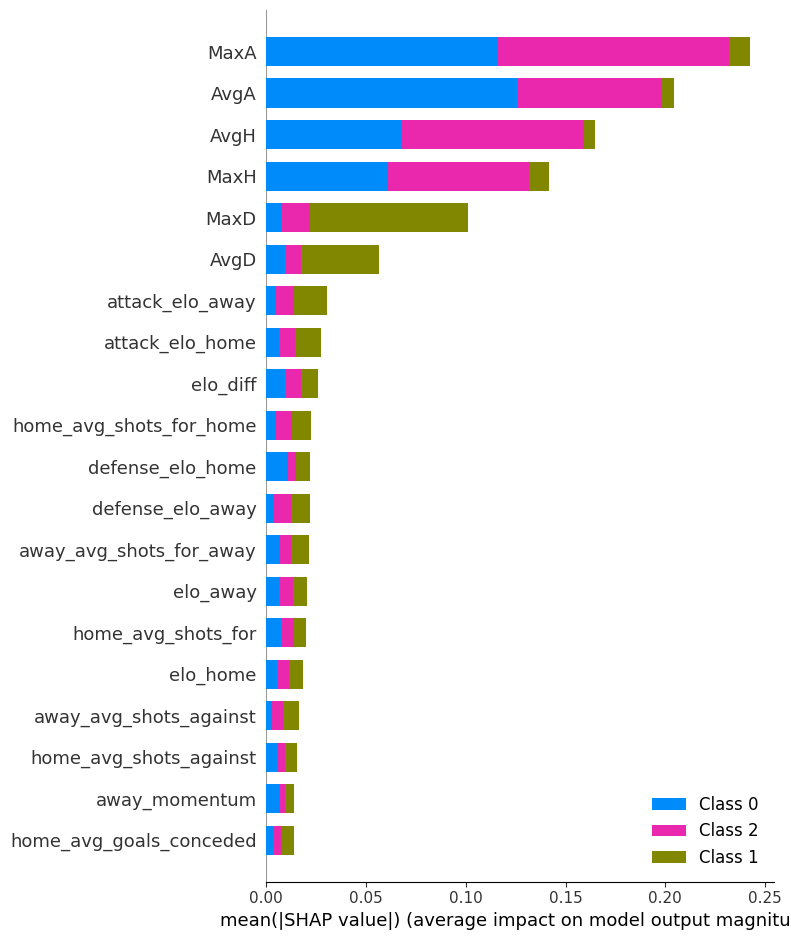

PermutationExplainer explainer: 2142it [18:38,  1.90it/s]                          


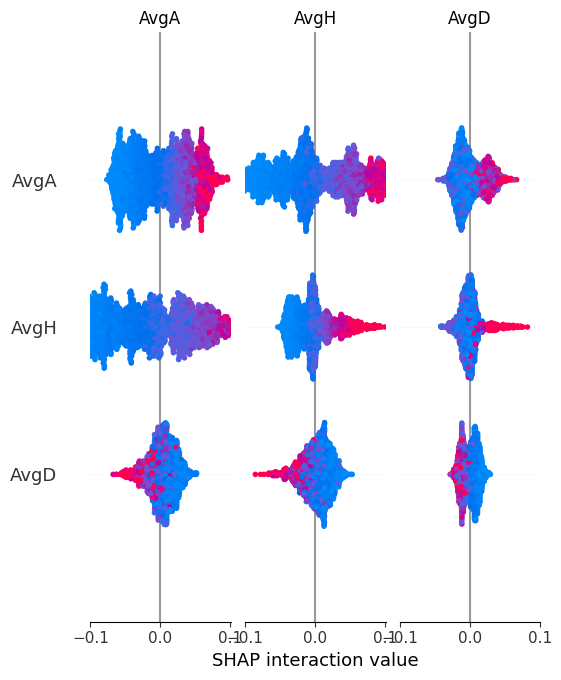

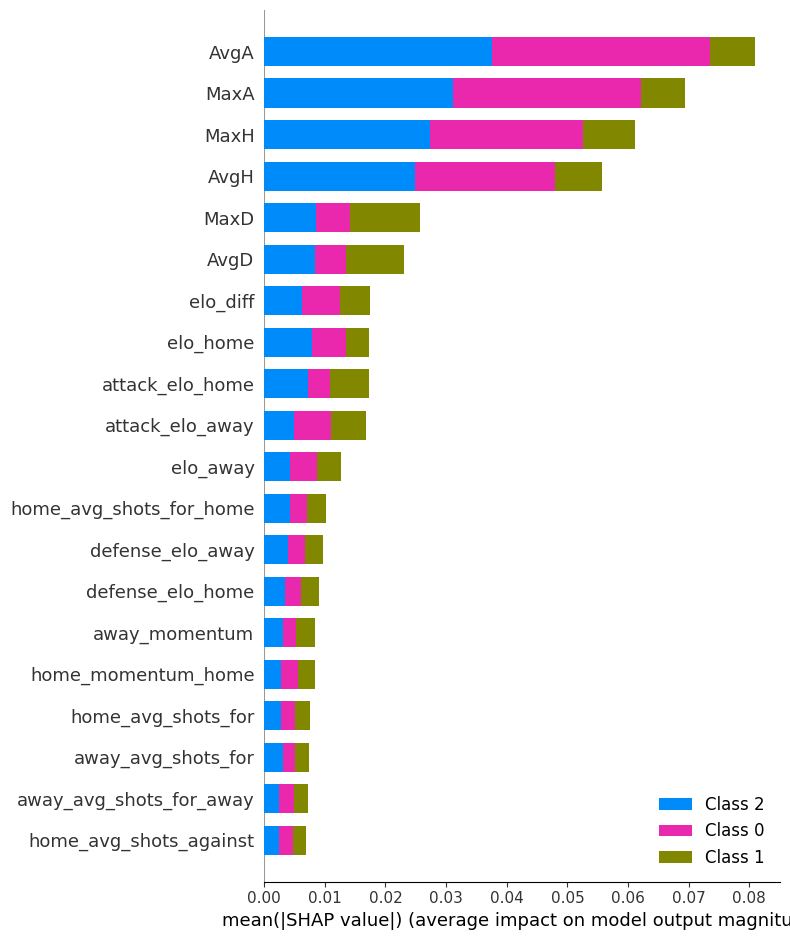

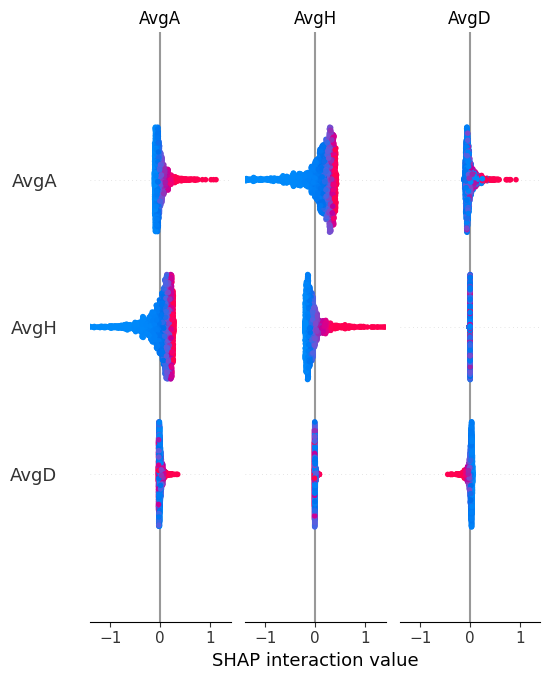

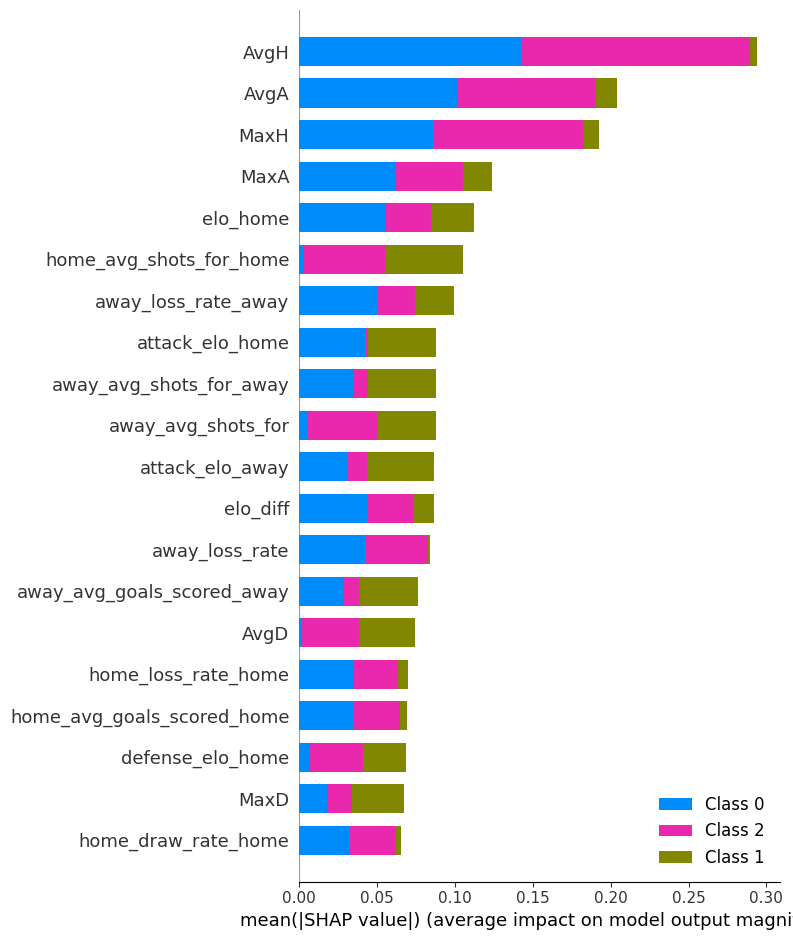

In [55]:
# ------------------------------------
# SHAP Analysis - Dataset B with odds
# ------------------------------------

# XGBoost SHAP analysis
explainer_xgb = shap.TreeExplainer(best_xgb_b_odds)
shap_values_xgb = explainer_xgb.shap_values(X_test_b_odds)
shap.summary_plot(shap_values_xgb, X_test_b_odds, feature_names=X_train_b_odds.columns)
plt.savefig("../results/figures/04_shap_xgb_b_odds.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_xgb, X_test_b_odds, feature_names=X_train_b_odds.columns, plot_type="bar")
plt.savefig("../results/figures/05_shap_bar_xgb_b_odds.png", dpi=300, bbox_inches='tight')
plt.close()

# Random Forest SHAP analysis
explainer_rf = shap.PermutationExplainer(best_rf_b_odds.predict_proba, X_train_b_odds)
shap_values_rf = explainer_rf(X_test_b_odds)
shap.summary_plot(shap_values_rf.values, X_test_b_odds, feature_names=X_train_b_odds.columns)
plt.savefig("../results/figures/06_shap_rf_b_odds.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_rf.values, X_test_b_odds, feature_names=X_train_b_odds.columns, plot_type="bar")
plt.savefig("../results/figures/07_shap_bar_rf_b_odds.png", dpi=300, bbox_inches='tight')
plt.close()

# Logistic Regression SHAP analysis
explainer_lr = shap.LinearExplainer(best_lr_b_odds, X_train_b_odds_scaled)
shap_values_lr = explainer_lr(X_test_b_odds_scaled)
shap.summary_plot(shap_values_lr.values, X_test_b_odds_scaled, feature_names=X_train_b_odds.columns)
plt.savefig("../results/figures/08_shap_lr_b_odds.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_lr.values, X_test_b_odds_scaled, feature_names=X_train_b_odds.columns, plot_type="bar")
plt.savefig("../results/figures/09_shap_bar_lr_b_odds.png", dpi=300, bbox_inches='tight')
plt.close()


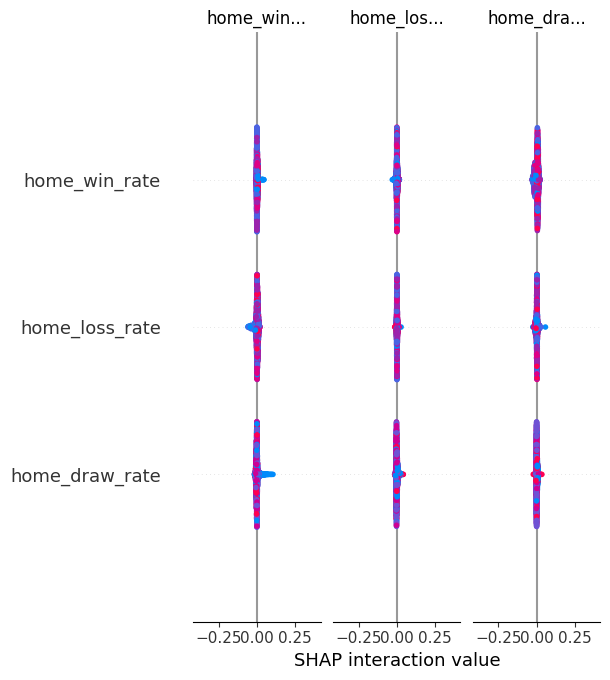

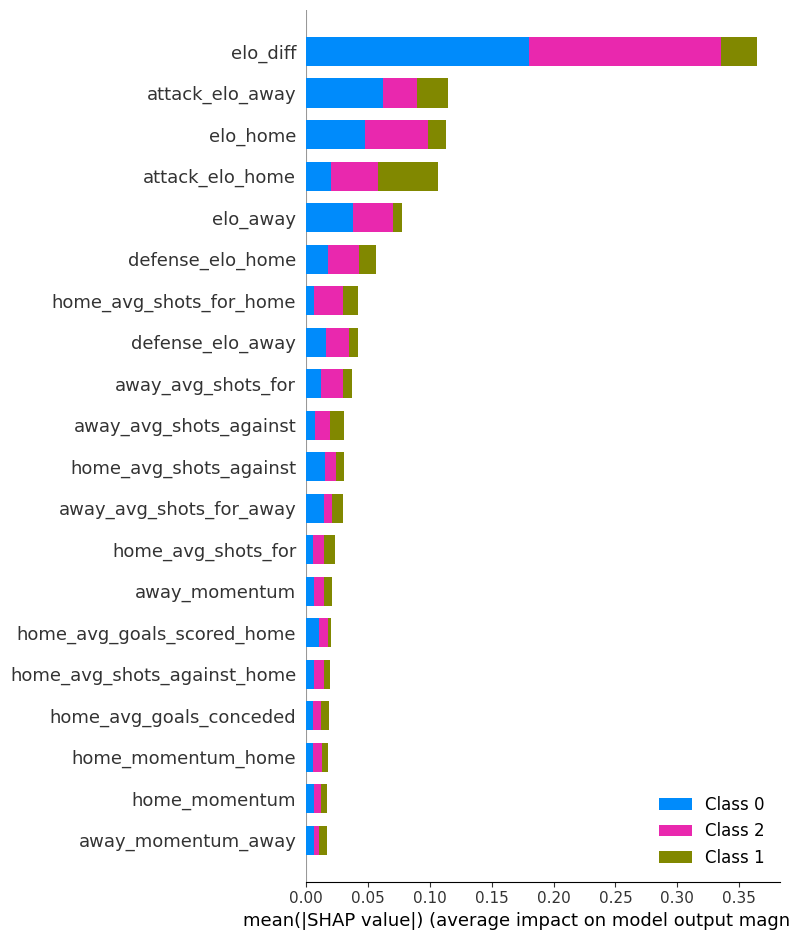

PermutationExplainer explainer: 2142it [14:55,  2.36it/s]                          


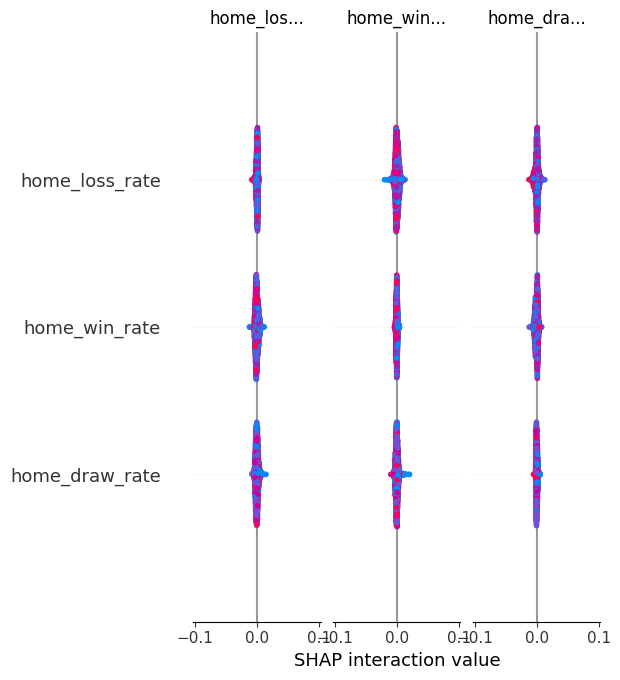

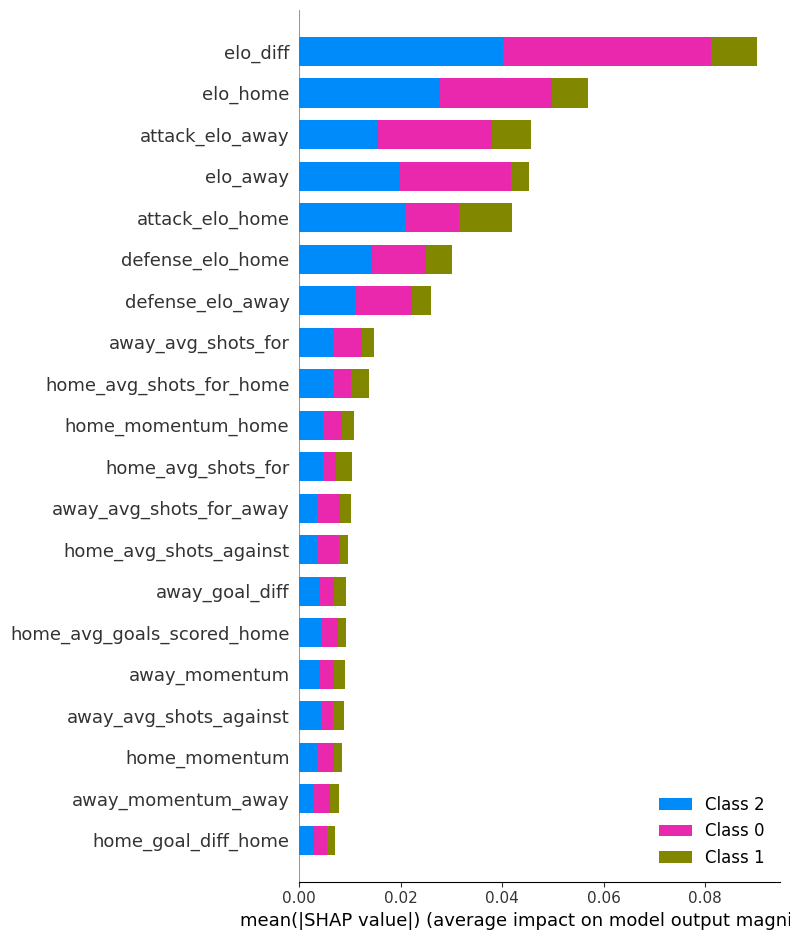

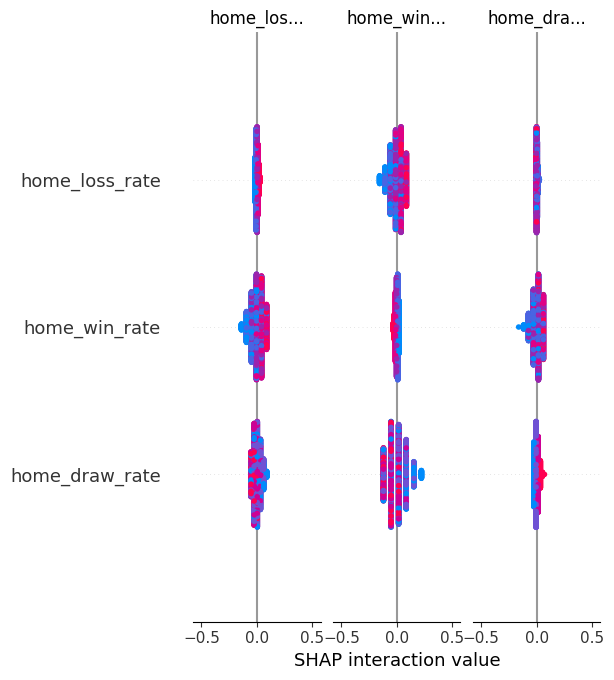

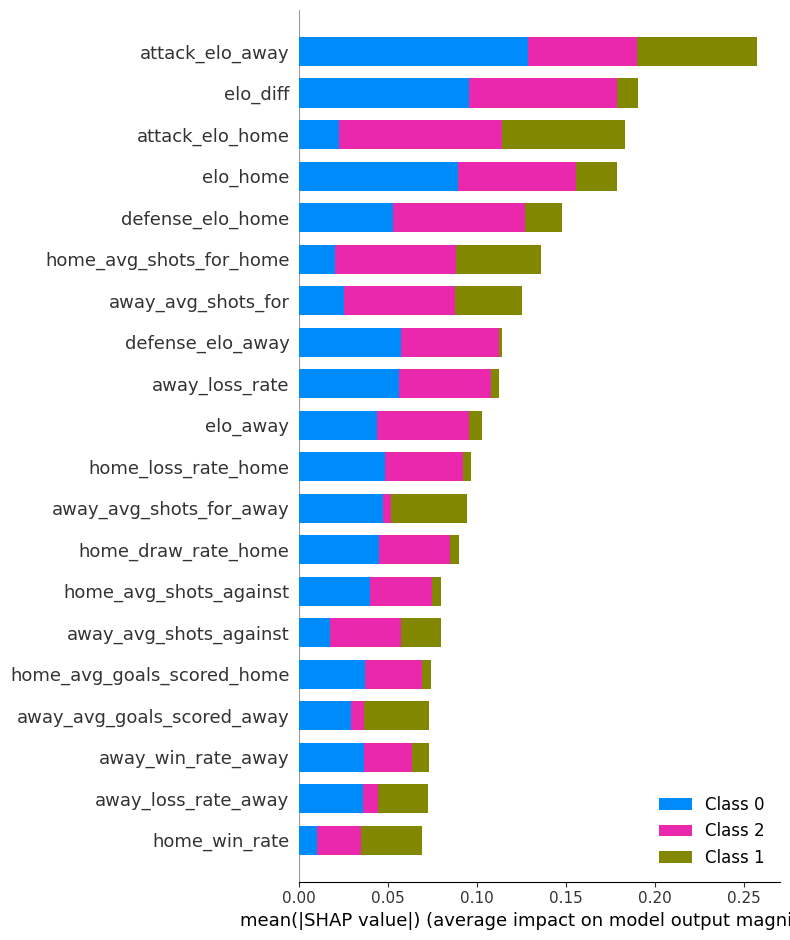

In [56]:
# ---------------------------------------
# SHAP Analysis - Dataset B without odds
# ---------------------------------------

# XGBoost SHAP analysis
explainer_xgb = shap.TreeExplainer(best_xgb_b_no_odds)
shap_values_xgb = explainer_xgb.shap_values(X_test_b_no_odds)
shap.summary_plot(shap_values_xgb, X_test_b_no_odds, feature_names=X_train_b_no_odds.columns)
plt.savefig("../results/figures/10_shap_xgb_b_no_odds.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_xgb, X_test_b_no_odds, feature_names=X_train_b_no_odds.columns, plot_type="bar")
plt.savefig("../results/figures/11_shap_bar_xgb_b_no_odds.png", dpi=300, bbox_inches='tight')
plt.close()

# Random Forest SHAP analysis
explainer_rf = shap.PermutationExplainer(best_rf_b_no_odds.predict_proba, X_train_b_no_odds)
shap_values_rf = explainer_rf(X_test_b_no_odds)
shap.summary_plot(shap_values_rf.values, X_test_b_no_odds, feature_names=X_train_b_no_odds.columns)
plt.savefig("../results/figures/12_shap_rf_b_no_odds.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_rf.values, X_test_b_no_odds, feature_names=X_train_b_no_odds.columns, plot_type="bar")
plt.savefig("../results/figures/13_shap_bar_rf_b_no_odds.png", dpi=300, bbox_inches='tight')
plt.close()

# Logistic Regression SHAP analysis
explainer_lr = shap.LinearExplainer(best_lr_b_no_odds, X_train_b_no_odds_scaled)
shap_values_lr = explainer_lr(X_test_b_no_odds_scaled)
shap.summary_plot(shap_values_lr.values, X_test_b_no_odds_scaled, feature_names=X_train_b_no_odds.columns)
plt.savefig("../results/figures/14_shap_lr_b_no_odds.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_lr.values, X_test_b_no_odds_scaled, feature_names=X_train_b_no_odds.columns, plot_type="bar")
plt.savefig("../results/figures/15_shap_bar_lr_b_no_odds.png", dpi=300, bbox_inches='tight')
plt.close()



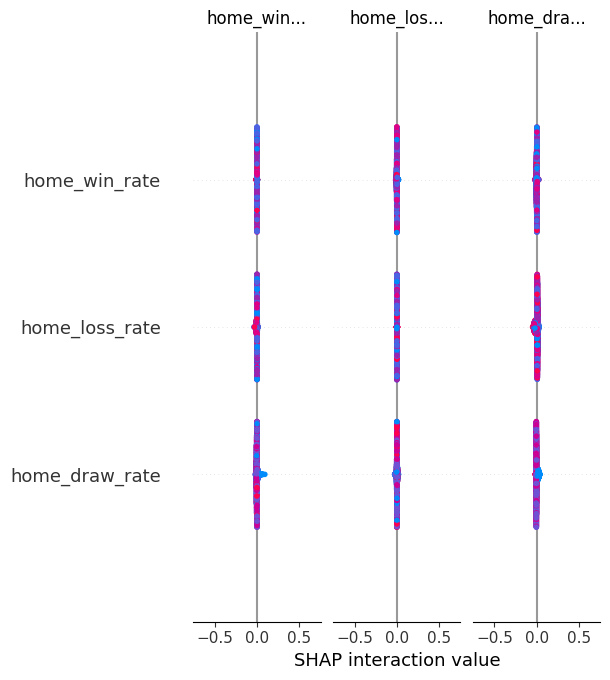

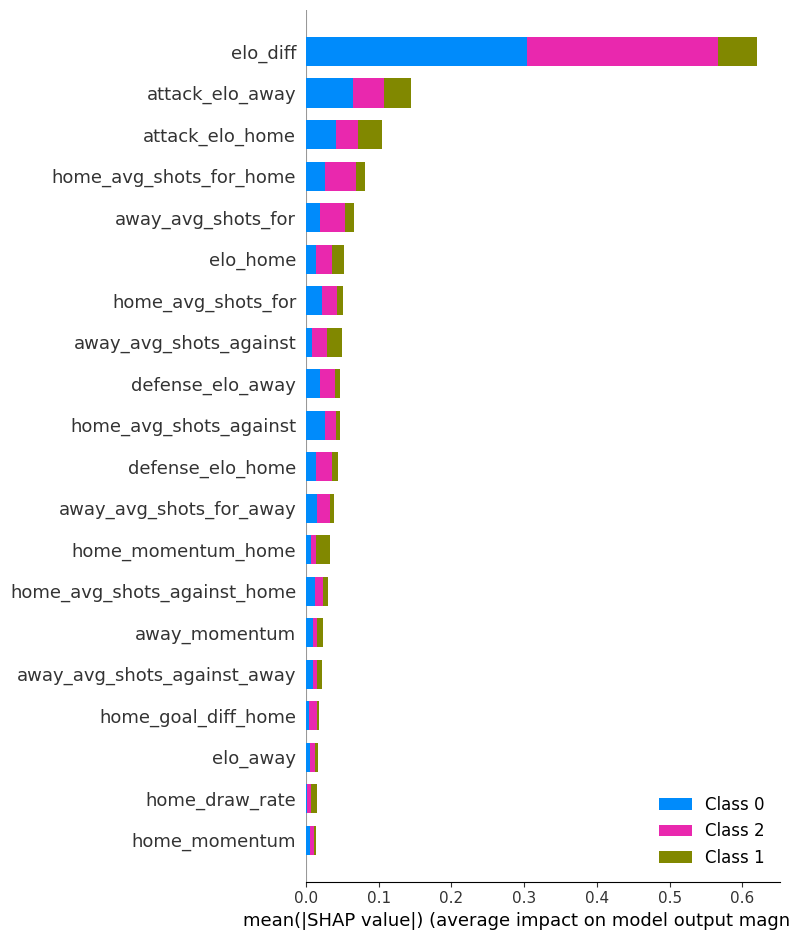

PermutationExplainer explainer: 3968it [27:31,  2.39it/s]                          


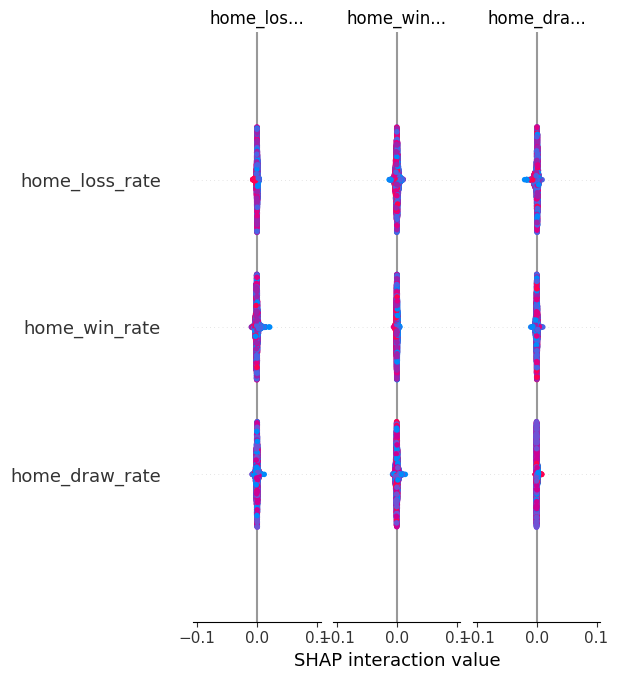

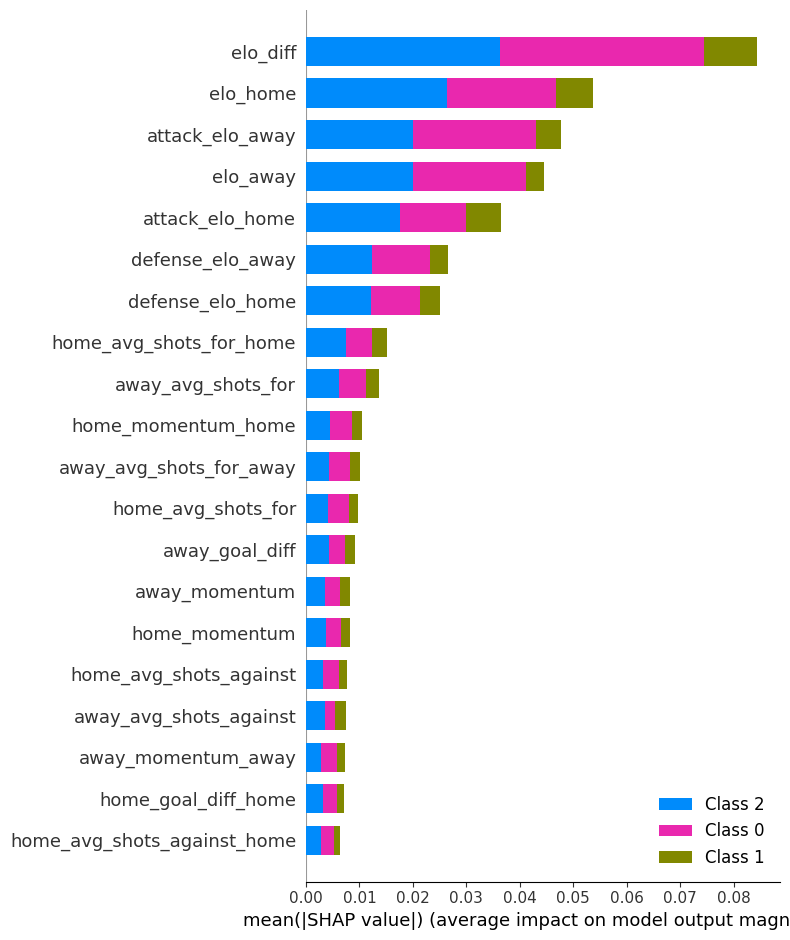

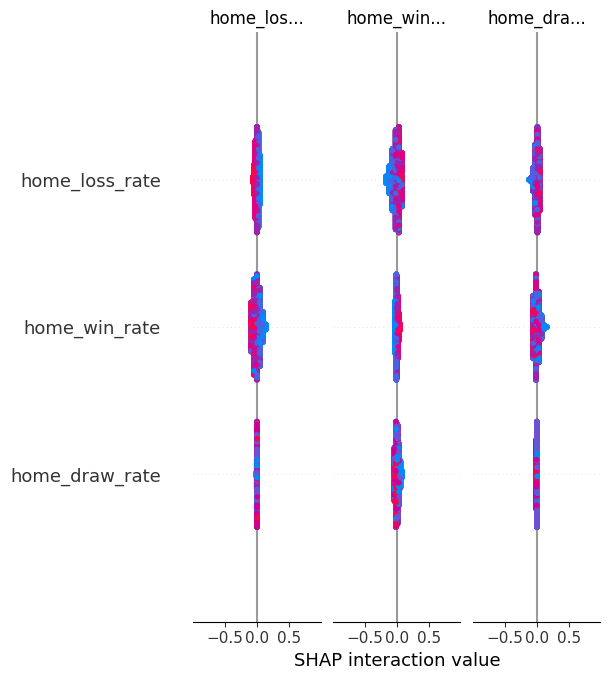

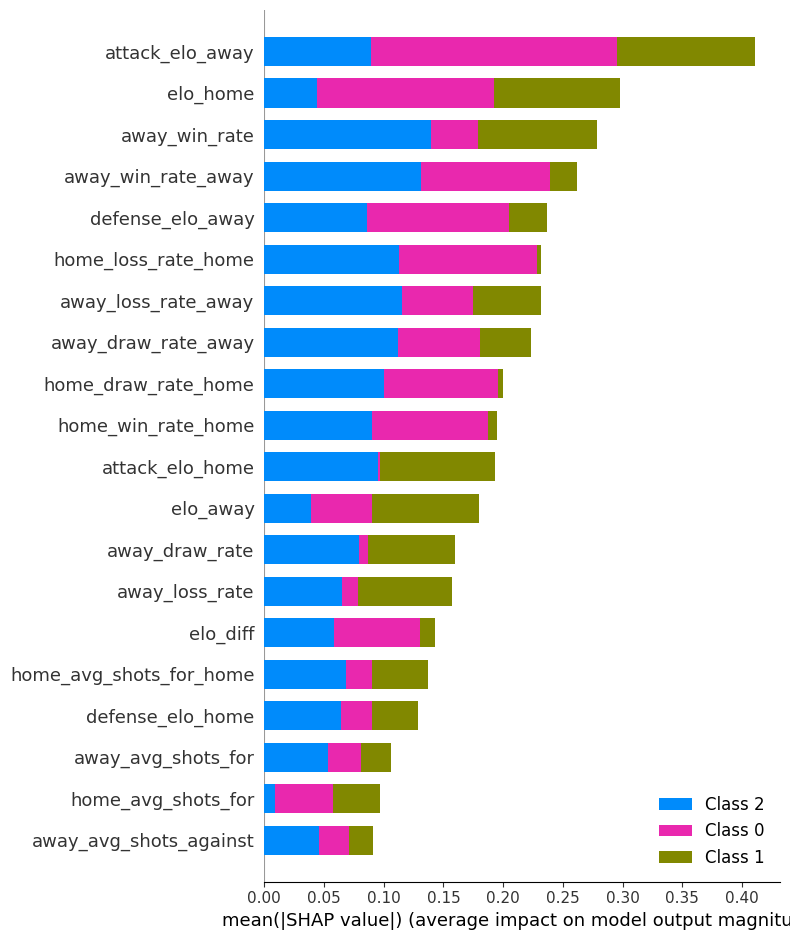

In [57]:
# --------------------------
# SHAP Analysis - Dataset A
# --------------------------

# XGBoost SHAP analysis
explainer_xgb = shap.TreeExplainer(best_xgb_a)
shap_values_xgb = explainer_xgb.shap_values(X_test_a)
shap.summary_plot(shap_values_xgb, X_test_a, feature_names=X_train_a.columns)
plt.savefig("../results/figures/16_shap_xgb_a.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_xgb, X_test_a, feature_names=X_train_a.columns, plot_type="bar")
plt.savefig("../results/figures/17_shap_bar_xgb_a.png", dpi=300, bbox_inches='tight')
plt.close()

# Random Forest SHAP analysis
explainer_rf = shap.PermutationExplainer(best_rf_a.predict_proba, X_train_a)
shap_values_rf = explainer_rf(X_test_a)
shap.summary_plot(shap_values_rf.values, X_test_a, feature_names=X_train_a.columns)
plt.savefig("../results/figures/18_shap_rf_a.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_rf.values, X_test_a, feature_names=X_train_a.columns, plot_type="bar")
plt.savefig("../results/figures/19_shap_bar_rf_a.png", dpi=300, bbox_inches='tight')
plt.close()

# Logistic Regression SHAP analysis
explainer_lr = shap.LinearExplainer(best_lr_a, X_train_a_scaled)
shap_values_lr = explainer_lr(X_test_a_scaled)
shap.summary_plot(shap_values_lr.values, X_test_a_scaled, feature_names=X_train_a.columns)
plt.savefig("../results/figures/20_shap_lr_a.png", dpi=300, bbox_inches='tight')
plt.close()
shap.summary_plot(shap_values_lr.values, X_test_a_scaled, feature_names=X_train_a.columns, plot_type="bar")
plt.savefig("../results/figures/21_shap_bar_lr_a.png", dpi=300, bbox_inches='tight')
plt.close()